# PricePulse BD — Stage 3: can next month's prices be forecast?

**Short answer: the level, no — the uncertainty, yes.**

Across ~40,000 out-of-sample forecasts (57 commodities, Feb 2023 – Nov 2026, 1–4 weeks
ahead) no model predicted prices better than *"the price stays where it is"*. What
machine learning does add is a better **range**: an 80% prediction interval that is
correctly calibrated and significantly sharper than each item's own historical
quantiles. So the product ships today's price as the central estimate with an
ML-built range around it.

This notebook shows how that conclusion was reached, and what would have to be true
for it to be wrong.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np
from IPython.display import display
from analysis import data
from forecast import panel, backtest as bt, figures as fg
from forecast.run import choose_point, choose_interval
pd.set_option("display.precision", 3)
%matplotlib inline

R = pd.read_parquet(data.OUTPUTS / "backtest_predictions.parquet")
E = bt.common_sample(R)
print(f"{len(E):,} scored forecasts · {E.commodity_id.nunique()} commodities · "
      f"origins {E.date.min():%d %b %Y} to {E.date.max():%d %b %Y}")

39,652 scored forecasts · 57 commodities · origins 02 Feb 2023 to 05 Nov 2026


## 1. Set-up

**Target.** The Thursday price *h* = 1…4 weeks ahead, as a log change from today's
Thursday price. Point-in-time prices, not weekly averages: averaging a random walk
creates artificial autocorrelation (Working, 1960) that would hand every model a free
win over the naive forecast.

**Why this is hard.** Retail prices here are sticky:

In [2]:
lp = panel.weekly_log_prices()
r1 = lp.diff()
pd.Series({
    "weeks with no price change (median item)": f"{(r1 == 0).mean().median():.0%}",
    "lag-1 autocorrelation of weekly changes (median item)": f"{r1.apply(lambda s: s.autocorr(1)).median():+.2f}",
    "typical 4-week move, |%| (mean over items)": f"{E[E.h == 4].y.abs().mean() * 100:.1f}%",
}).to_frame("value")

,value
weeks with no price change (median item),63%
lag-1 autocorrelation of weekly changes (median item),-0.05
"typical 4-week move, |%| (mean over items)",3.9%


In about two weeks out of three the price doesn't move at all, and when it does, the
move is almost uncorrelated with the previous one. That is close to a random walk —
for which the best forecast is the last observed price.

**Models compared**

| Model | Idea |
|---|---|
| Naive | next price = today's price |
| Naive + drift | add the item's average weekly change over the past year |
| Seasonal naive | repeat what the item did over the same weeks last year |
| Exponential smoothing | ETS(A,N,N), smoothing weight re-chosen at every origin |
| Gradient boosting (mean) | one pooled model per horizon, 25 features, volatility-scaled target |
| Gradient boosting (median) | same, trained on absolute-error (quantile 0.5) loss |

**Protocol.** Rolling origin: every model forecasts from every Thursday as if live.
Expanding training window; the boosted models are refit every 13 weeks using only rows
whose outcome was already known. A look-ahead test (`tests/test_no_leakage.py`)
rebuilds all features with the future deleted and requires them to be identical.

**Decision rules, fixed in code before the results were read** (`forecast/run.py`):
ship a model's point forecast only if it beats naive with Diebold–Mariano p < 0.05;
ship the interval method with the lowest interval score among those within ±3 points
of 80% coverage at every horizon.

## 2. Point forecasts: nothing beats "no change"

weeks ahead,1,2,3,4
model,,,,
naive,1.000,1.000,1.000,1.000
ses,1.035,1.016,1.008,1.006
gbm_median,1.008,1.012,1.021,1.034
drift,1.117,1.118,1.121,1.127
gbm,1.286,1.270,1.221,1.235
seasonal,1.829,1.733,1.668,1.629


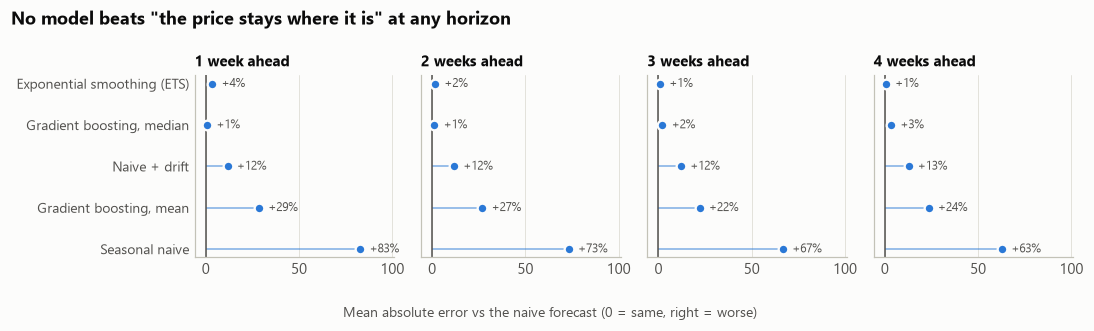

In [3]:
point = bt.point_metrics(E)
display(point.pivot(index="model", columns="h", values="rel_mae")
             .loc[["naive", "ses", "gbm_median", "drift", "gbm", "seasonal"]]
             .rename_axis(columns="weeks ahead").style.format("{:.3f}")
             .set_caption("MAE relative to naive (below 1 = better than naive)"))
fg.point_skill(point);

In [4]:
dm = pd.concat([bt.diebold_mariano(E, m) for m in bt.POINT_MODELS if m != "naive"])
display(dm.pivot(index="model", columns="h", values="dm_stat").round(1)
          .rename_axis(columns="weeks ahead")
          .style.set_caption("Diebold-Mariano statistic vs naive (positive = significantly worse than naive)"))
print("Point model chosen by the rule:", choose_point(point, dm))

weeks ahead,1,2,3,4
model,,,,
drift,32.400000,21.200000,16.900000,14.400000
gbm,20.900000,12.900000,11.800000,10.400000
gbm_median,4.200000,3.500000,4.600000,3.900000
seasonal,21.800000,21.500000,20.500000,19.000000
ses,11.200000,8.400000,5.500000,4.300000


Point model chosen by the rule: {1: 'naive', 2: 'naive', 3: 'naive', 4: 'naive'}


Every alternative is *significantly worse* than naive at every horizon.

* **Seasonal naive is the worst (+63–83%).** With only six years of history and
  shocks in most of them, "what happened last year" is mostly noise.
* **The mean-trained boosted model loses by 22–29%.** It predicts small non-zero
  changes for prices that mostly don't move; each of those is a small error.
* **Training the same model for the median** (the correct target under absolute
  error — Gneiting, 2011) closes almost all of that gap, to within 1–3% of naive.
  It gets there by predicting "no change" 74–98% of the time: it has *learned* the
  naive forecast.

Is there a pocket where ML helps?

In [5]:
pi = bt.per_item(E, "gbm_median")
pi["name"] = pi.commodity_id.map(data.commodities().name_en)
print("commodities where the median model beats naive, by horizon:",
      pi[pi.rel_mae < 1].groupby("h").size().to_dict(), "of", pi.commodity_id.nunique())
best = pi[pi.h == 4].nsmallest(6, "rel_mae")[["name", "n", "mae_naive", "rel_mae"]]
best["mae_naive"] *= 100
best.rename(columns={"mae_naive": "typical 4-week move %", "rel_mae": "MAE vs naive"})

commodities where the median model beats naive, by horizon: {1: 5, 2: 3, 3: 9, 4: 9} of 57


,name,n,typical 4-week move %,MAE vs naive
176,Brinjal,33,21.584,0.936
178,"Chicken, broiler",187,6.365,0.937
186,Cucumber,33,27.710,0.978
222,"Soybean oil, bottle 2 L",100,0.928,0.980
227,"Turmeric, local",187,3.512,0.984
194,Green chilli,21,27.211,0.986


A handful — broiler chicken is the clearest (≈6% better at 4 weeks), plausibly
because its short production cycle makes prices mean-revert. But picking the winners
*after* seeing the backtest is exactly how forecasting projects fool themselves, so
they are noted as a lead for future work, not shipped.

**Finding 1.** At 1–4 weeks, Dhaka retail prices behave like a random walk. The honest
central forecast is today's price.

## 3. Prediction intervals: where ML earns its place

If the level can't be forecast, the useful question becomes *how far might it move?*
Four ways to build an 80% range:

| Method | Idea |
|---|---|
| Item's own past changes | 10th–90th percentile of the item's own h-week changes, last 2 years |
| ML quantiles, raw | boosted quantile regression (10% / 90%), pooled across items |
| ML + conformal (pooled) | widen/narrow the raw range by last year's out-of-sample misses |
| ML + conformal (per item) | same, each item corrected by its own misses |

weeks ahead,1,2,3,4
method,,,,
Item's own past changes,85.5%,83.4%,82.0%,81.7%
"ML quantiles, raw",80.1%,78.3%,76.3%,74.5%
ML + conformal (pooled),79.6%,80.8%,80.1%,80.6%
ML + conformal (per item),79.2%,80.0%,79.2%,78.8%


Interval method chosen by the rule: gbm_cqr


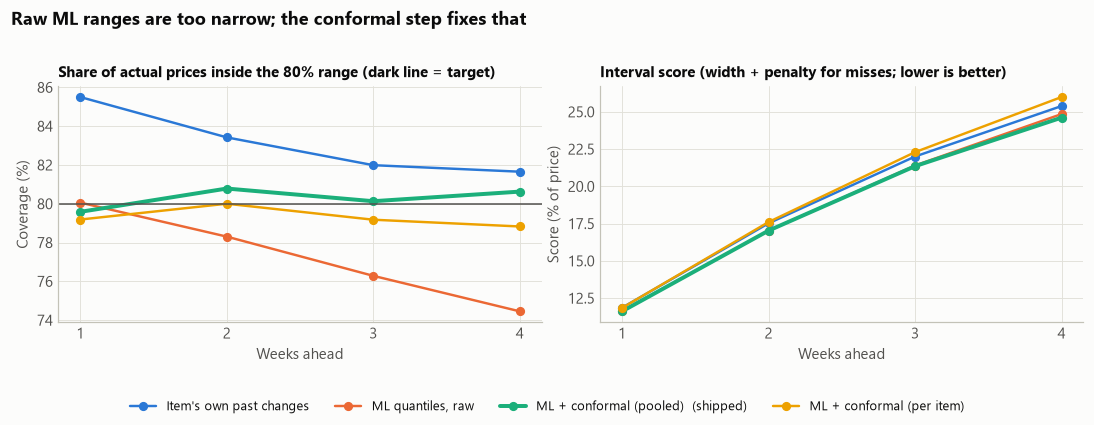

In [6]:
iv = bt.interval_metrics(E)
chosen = choose_interval(iv)
display(iv.pivot(index="method", columns="h", values="coverage").loc[bt.INTERVALS]
          .rename(index=fg.METHOD_LABEL).rename_axis(columns="weeks ahead")
          .style.format("{:.1%}").set_caption("Coverage of the nominal 80% range"))
print("Interval method chosen by the rule:", chosen)
fg.interval_calibration(iv, chosen);

In [7]:
dmi = pd.concat([bt.dm_interval(E, m) for m in bt.INTERVALS if m != "empirical"])
dmi.pivot(index="method", columns="h", values="p_value").rename(index=fg.METHOD_LABEL).round(4) \
   .rename_axis(columns="weeks ahead") \
   .style.set_caption("p-value: interval score vs the item's-own-history baseline")

weeks ahead,1,2,3,4
method,,,,
ML + conformal (pooled),0.003700,0.000700,0.011500,0.043100
ML + conformal (per item),0.909300,0.586500,0.275000,0.104200
"ML quantiles, raw",0.004500,0.000700,0.024300,0.217700


* **Raw ML ranges are overconfident** — coverage decays to 74% at four weeks.
* **The conformal step repairs that** (79.6–80.8% at every horizon) and scores better
  than the historical-quantile baseline at all four horizons (p ≤ 0.043). At 2–4 weeks
  the ranges are also 3–7% narrower; at 1 week they are about as wide but miss by less.
* The gain is real but **modest**: about a 2–3% better interval score.

Why is the ML range sharper? Because it is *conditional*: it widens when an item has
just been volatile and narrows when it has been calm, instead of using one fixed
width per item.

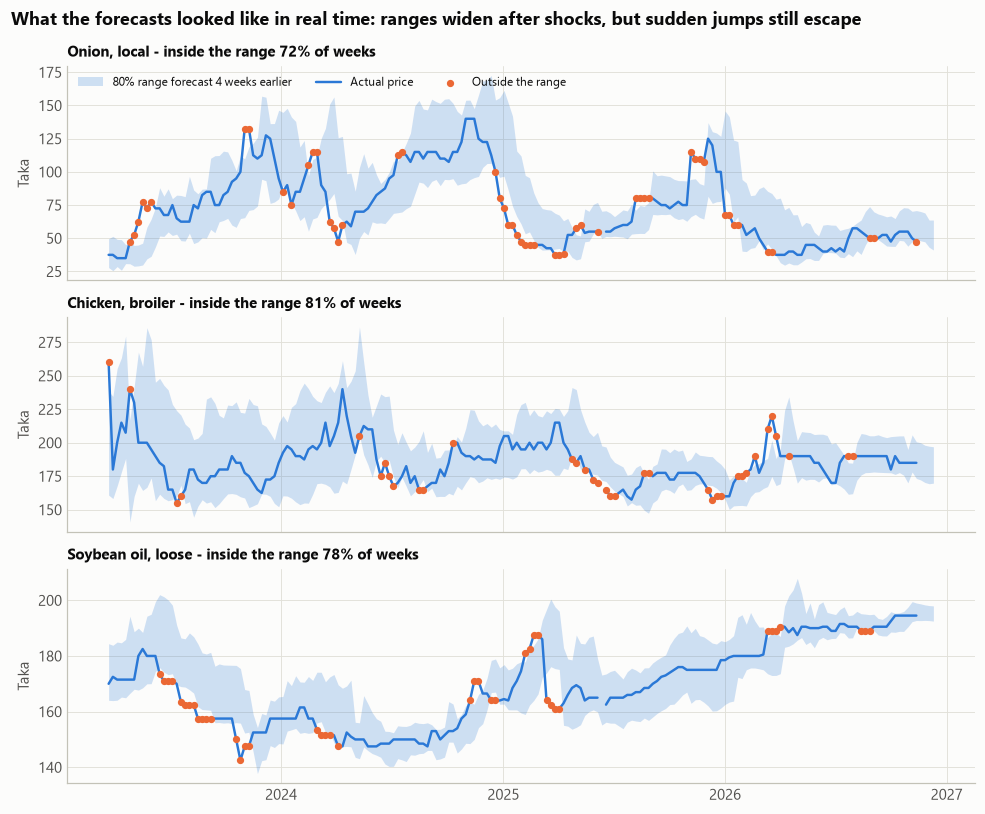

In [8]:
fg.backtest_bands(R, chosen, ["onion_local", "chicken_broiler", "soybean_loose"]);

### Is the range honest for each item, or only on average?

Pooled calibration can hide items that are badly served.

,items,median_item_coverage,min_item_coverage,share_items_70_90
method,,,,
Item's own past changes,54,81.6%,69.0%,91%
"ML quantiles, raw",54,74.9%,61.0%,78%
ML + conformal (pooled),54,81.3%,65.2%,93%
ML + conformal (per item),54,79.3%,70.4%,98%


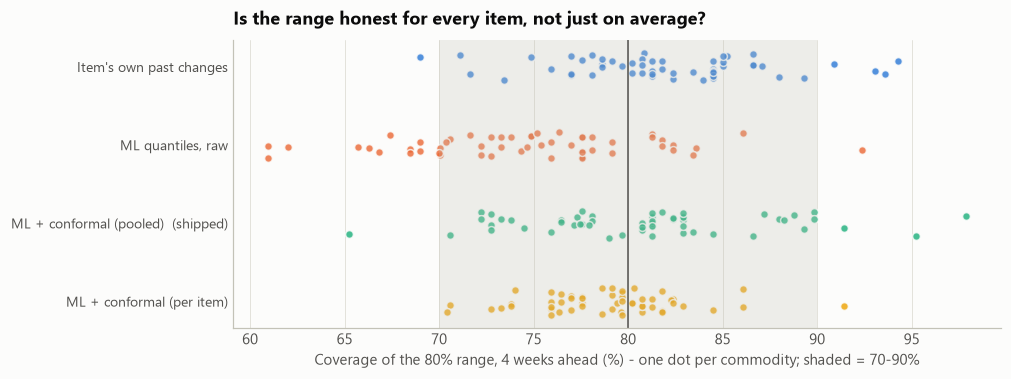

In [9]:
cal = bt.item_calibration(E)
display(cal[cal.h == 4].set_index("method").loc[bt.INTERVALS].rename(index=fg.METHOD_LABEL)
          [["items", "median_item_coverage", "min_item_coverage", "share_items_70_90"]]
          .style.format({"median_item_coverage": "{:.1%}", "min_item_coverage": "{:.1%}",
                         "share_items_70_90": "{:.0%}"})
          .set_caption("Per-commodity coverage, 4 weeks ahead"))
fg.item_coverage(E, chosen);

In [10]:
c = bt.coverage_by_item(E, chosen).merge(E.groupby(["h", "commodity_id"]).size().rename("n").reset_index())
c = c[c.n >= 52].assign(name=lambda d: d.commodity_id.map(data.commodities().name_en))
c.nsmallest(6, "coverage")[["name", "h", "n", "coverage"]]

,name,h,n,coverage
45,"Rice bran oil, bottle 5 L",1,73,0.479
225,Sugar,4,187,0.652
36,"Onion, imported",1,109,0.688
17,"Dates (khejur), regular",1,193,0.694
130,Cumin,3,189,0.698
150,"Onion, imported",3,104,0.702


**A real trade-off, reported rather than hidden.** The shipped (pooled) method has the
best overall score, but a few items are under-covered — sugar's "80%" range held only
65% of the time at four weeks, and rice-bran oil (short history) 48% at one week. The
per-item variant fixes this (98% of items land in the 70–90% band) at the cost of
~15% wider ranges and a worse overall score. The pre-set rule picked the pooled
method; the website shows each item's *own* backtest coverage next to its range so
nobody has to take "80%" on trust.

**Finding 2.** ML adds value as an uncertainty model: calibrated, and significantly —
if modestly — sharper than history alone.

## 4. What drives the range?

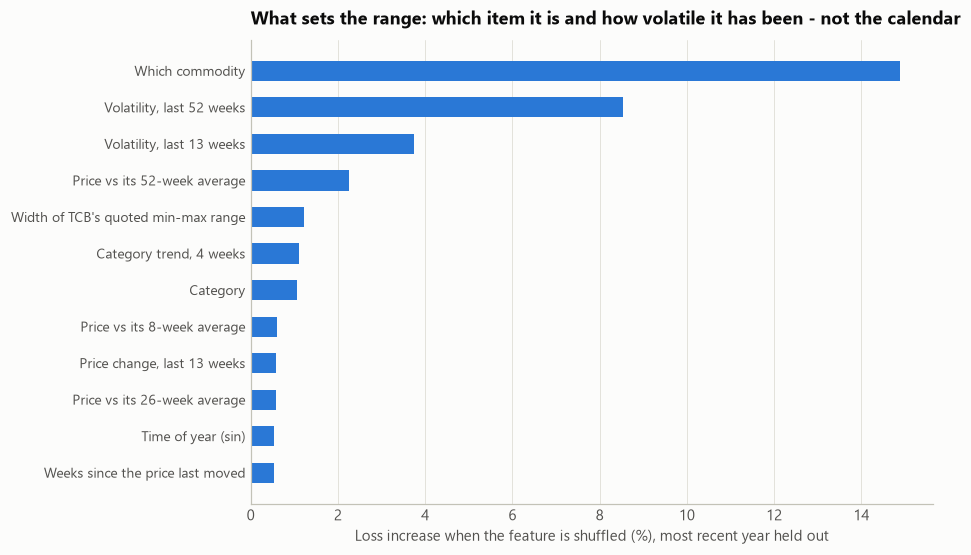

In [11]:
imp = pd.read_csv(data.OUTPUTS / "forecast_feature_importance.csv", index_col=0)
fg.importance(imp);

Permutation importance on the most recent year (held out): the model mostly needs to
know *which item* it is looking at and *how volatile that item has been lately*.
Calendar and festival features barely register — consistent with Stage 2, where
festival effects were real for meat but small next to ordinary week-to-week noise.

## 5. The forecast

Origin 2026-11-12 · 53 commodities · interval: ML + conformal (pooled) · central estimate: today's price


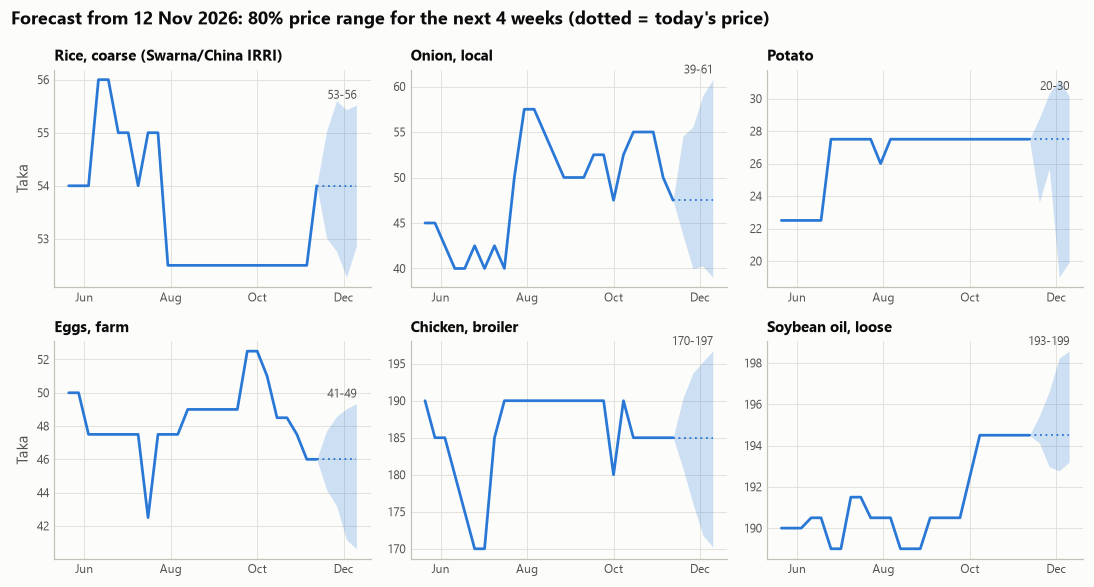

In [12]:
F = pd.read_csv(data.OUTPUTS / "forecasts.csv")
meta = json.loads((data.OUTPUTS / "forecasts.json").read_text(encoding="utf-8"))
print(f"Origin {meta['origin']} · {F.commodity_id.nunique()} commodities · "
      f"interval: {fg.METHOD_LABEL[meta['interval_method']]} · central estimate: today's price")
fg.forecast_fan(F, ["rice_coarse", "onion_local", "potato", "eggs", "chicken_broiler", "soybean_loose"]);

In [13]:
core = data.core_ids()
t = F[(F.h == 4) & F.commodity_id.isin(core)].copy()
t["name"] = t.commodity_id.map(data.commodities().name_en)
t["range (Tk)"] = t.lo.round(0).astype(int).astype(str) + " – " + t.hi.round(0).astype(int).astype(str)
t["range (%)"] = t.lo_pct.round(0).astype(int).astype(str) + "% … +" + t.hi_pct.round(0).astype(int).astype(str) + "%"
(t.assign(width=t.hi_pct - t.lo_pct).sort_values("width", ascending=False)
  [["name", "price_now", "range (Tk)", "range (%)", "backtest_coverage"]]
  .rename(columns={"price_now": "price now (Tk)", "backtest_coverage": "this item's backtest coverage"})
  .style.format({"price now (Tk)": "{:.0f}", "this item's backtest coverage": "{:.0%}"}).hide(axis="index")
  .set_caption("80% price range four weeks ahead, core basket"))

name,price now (Tk),range (Tk),range (%),this item's backtest coverage
"Onion, local",47,39 – 61,-18% … +28%,72%
Potato,28,20 – 30,-28% … +10%,73%
"Garlic, local",110,91 – 119,-17% … +9%,81%
"Ginger, imported",170,147 – 188,-14% … +10%,73%
Hilsa (ilish),1350,1256 – 1512,-7% … +12%,77%
"Eggs, farm",46,41 – 49,-12% … +7%,76%
"Chicken, broiler",185,170 – 197,-8% … +6%,81%
"Dates (khejur), regular",450,424 – 482,-6% … +7%,83%
Chickpea (chola),115,110 – 120,-5% … +4%,73%
"Atta, loose",49,47 – 52,-3% … +5%,74%


## 6. Limitations

* **Only six years, one city.** Annual patterns are seen five or six times, each in a
  different shock year; a longer history could reveal seasonality that is invisible here.
* **Min–max midpoints, not transactions.** TCB reports a quoted range; its midpoint
  moves in steps, which is part of why "no change" is so often right.
* **No external drivers.** Exchange rate, world commodity prices, import duties and
  weather are not in the model. Sudden policy shocks (export bans) cannot be
  anticipated from price history — the backtest bands show them escaping the range.
* **Horizons are modelled separately**, so a 3-week range is not forced to sit inside
  the 4-week range.
* **Calibration is on average.** Coverage is ~80% over all items and weeks; at four
  weeks individual items range from 65% to 98% (shown per item on the site).
* **One backtest, one set of hyper-parameters.** The boosted model was not tuned; a
  tuned or richer model might do better, but tuning on this same test period would
  make the comparison meaningless.

## Summary

| Question | Answer |
|---|---|
| Can a model beat "price stays the same" at 1–4 weeks? | **No** — every alternative is significantly worse (39,652 forecasts) |
| Best ML point forecast | median-trained boosting, 1–3% worse than naive; it mostly predicts "no change" |
| Does ML help anywhere? | **Yes, on uncertainty:** conformal ML ranges hit 80% coverage and beat historical quantiles at all horizons (p ≤ 0.043) |
| What is shipped | today's price + 80% ML range, with each item's own backtest coverage disclosed |

**Next (Stage 4):** the website — price explorer, spike alerts, festival effects and
these forecasts, refreshed daily by a GitHub Action and deployed on Vercel.